In [28]:
# Quick Comparison: Reconstruction AE vs Forecasting AE
# Minimal training to validate concept before full implementation
# Uses YOUR actual SequenceAutoencoder architecture

import os
import sys
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from pathlib import Path

# Setup paths
NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent
sys.path.insert(0, str(PROJECT_ROOT))

# Import YOUR actual model
from src.models.autoencoder import SequenceAutoencoder, Conv1dEncoder

# Config - USE YOUR ACTUAL PARAMETERS
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

# YOUR ACTUAL PARAMETERS (from params_validated_ae.yaml)
W = 16              # YOUR window size
BATCH_SIZE = 256
EPOCHS = 5          # Short test
LR = 1e-3           # YOUR learning rate
LATENT_DIM = 16     # YOUR latent dimension
INPUT_DIM = 86      # YOUR input dimension (86 features after preprocessing)

print(f"Device: {DEVICE}")
print(f"Config: W={W}, latent={LATENT_DIM}, epochs={EPOCHS}, lr={LR}, input_dim={INPUT_DIM}")
print("Using YOUR actual SequenceAutoencoder architecture")

Device: cpu
Config: W=16, latent=16, epochs=5, lr=0.001, input_dim=86
Using YOUR actual SequenceAutoencoder architecture


In [29]:
# Load processed data
import numpy as np
from torch.utils.data import DataLoader, TensorDataset

processed_dir = PROJECT_ROOT / "data" / "processed"

# Check if processed data exists
for fname in ["train.npy", "val_normal.npy", "val_anomaly.npy"]:
    fpath = processed_dir / fname
    if not fpath.exists():
        print(f"MISSING: {fpath}")
    else:
        print(f"Found: {fname}")

train_data = np.load(processed_dir / "train.npy")
val_normal_data = np.load(processed_dir / "val_normal.npy")
val_anomaly_data = np.load(processed_dir / "val_anomaly.npy")

print(f"Train: {train_data.shape}")
print(f"Val normal: {val_normal_data.shape}")
print(f"Val anomaly: {val_anomaly_data.shape}")

# Create sliding windows
def make_windows(data, window_size, stride=1):
    n = len(data)
    windows = []
    for i in range(0, n - window_size + 1, stride):
        windows.append(data[i:i+window_size])
    return np.stack(windows)

# Use stride=1 for maximum data (like your real training)
STRIDE = 1
train_windows = make_windows(train_data, W, STRIDE)
val_normal_windows = make_windows(val_normal_data, W, STRIDE)
val_anomaly_windows = make_windows(val_anomaly_data, W, STRIDE)

print(f"Train windows: {train_windows.shape}")
print(f"Val normal windows: {val_normal_windows.shape}")
print(f"Val anomaly windows: {val_anomaly_windows.shape}")

# Create DataLoaders
train_tensor = torch.from_numpy(train_windows).float()
val_normal_tensor = torch.from_numpy(val_normal_windows).float()
val_anomaly_tensor = torch.from_numpy(val_anomaly_windows).float()

train_loader = DataLoader(TensorDataset(train_tensor), batch_size=BATCH_SIZE, shuffle=True)
val_normal_loader = DataLoader(TensorDataset(val_normal_tensor), batch_size=BATCH_SIZE, shuffle=False)
val_anomaly_loader = DataLoader(TensorDataset(val_anomaly_tensor), batch_size=BATCH_SIZE, shuffle=False)

print(f"Train batches: {len(train_loader)}")
print(f"Val normal batches: {len(val_normal_loader)}")
print(f"Val anomaly batches: {len(val_anomaly_loader)}")

Found: train.npy
Found: val_normal.npy
Found: val_anomaly.npy
Train: (163654, 86)
Val normal: (35068, 86)
Val anomaly: (20769, 86)
Train windows: (163639, 16, 86)
Val normal windows: (35053, 16, 86)
Val anomaly windows: (20754, 16, 86)
Train batches: 640
Val normal batches: 137
Val anomaly batches: 82


In [30]:
# ============================================================
# MODEL 1: RECONSTRUCTION AE (YOUR ACTUAL SequenceAutoencoder)
# ============================================================

# Use YOUR actual SequenceAutoencoder
recon_ae = SequenceAutoencoder(
    input_dim=INPUT_DIM,
    window_size=W,
    latent_dim=LATENT_DIM,
)
print(f"Reconstruction AE params: {sum(p.numel() for p in recon_ae.parameters()):,}")

# ============================================================
# MODEL 2: FORECASTING AE (SAME ENCODER, FORECASTING HEAD)
# ============================================================

class ForecastingHead(nn.Module):
    """Forecasting head: takes global latent summary, predicts next step"""
    def __init__(self, latent_dim, input_dim, hidden=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(latent_dim, 128), nn.ReLU(),
            nn.Linear(128, input_dim)
        )
    
    def forward(self, z_global):
        return self.net(z_global)

class ForecastingAE(nn.Module):
    """
    Forecasting AE: SAME encoder as your SequenceAutoencoder,
    but replaces decoder with forecasting head that predicts t+1.
    """
    def __init__(self, input_dim, window_size, latent_dim):
        super().__init__()
        # Use SAME encoder as your SequenceAutoencoder
        self.encoder = Conv1dEncoder(
            input_dim=input_dim,
            window_size=W,
            latent_dim=latent_dim,
        )
        # Forecasting head: takes global latent summary, predicts t+1
        self.forecast_head = ForecastingHead(latent_dim, input_dim)
        
    def forward(self, x):
        # x: (B, input_dim, W) - history window
        # We predict t+1 given history x[:, :, :-1]
        history = x[:, :, :-1]          # (B, C, W-1) - history without last step
        z = self.encoder(history)       # (B, latent_dim, (W-1)/4)
        z_global = z.mean(dim=2)        # (B, latent_dim) - global avg pooling over time
        pred = self.forecast_head(z_global)  # (B, input_dim) - predicts next step
        return pred
    
    def compute_loss(self, x):
        # x: (B, input_dim, W)
        history = x[:, :, :-1]          # (B, C, W-1) - history
        target = x[:, :, -1]            # (B, C) - next step to predict
        pred = self.forward(x)          # (B, C) - prediction
        return F.mse_loss(pred, target)  # MSE on t+1 prediction

# Print model info
forecast_ae = ForecastingAE(INPUT_DIM, W, LATENT_DIM)
print(f"Forecasting AE params: {sum(p.numel() for p in forecast_ae.parameters()):,}")
print(f"Encoder params: {sum(p.numel() for p in forecast_ae.encoder.parameters()):,}")
print(f"Forecast head params: {sum(p.numel() for p in forecast_ae.forecast_head.parameters()):,}")
print(f"\nReconstruction AE encoder params: {sum(p.numel() for p in recon_ae.encoder.parameters()):,}")

# Verify encoders are identical
print(f"\nEncoders identical? {sum(p.numel() for p in recon_ae.encoder.parameters()) == sum(p.numel() for p in forecast_ae.encoder.parameters())}")

print("Models defined with YOUR actual encoder architecture.")

Reconstruction AE params: 62,518
Forecasting AE params: 48,854
Encoder params: 35,584
Forecast head params: 13,270

Reconstruction AE encoder params: 35,584

Encoders identical? True
Models defined with YOUR actual encoder architecture.


In [58]:
# ============================================================
# MODEL 2.5: VARADE-STYLE FORECASTING AE
# ============================================================
# Modello autoregressivo che cattura dynamics temporali sul latent sequence
# Ha raggiunto AUC 0.844 in Mascolini (DAC 2024) vs 0.810 AE baseline
# ============================================================

class VaradeAE(nn.Module):
    """
    VARADE-style Forecasting AE: uses autoregressive mechanism
    on the latent sequence to predict t+1.
    Ha raggiunto AUC 0.844 in Mascolini (DAC 2024) vs 0.810 per AE baseline.
    """
    def __init__(self, input_dim, window_size, latent_dim):
        super().__init__()
        # Use SAME encoder as your SequenceAutoencoder
        self.encoder = Conv1dEncoder(
            input_dim=input_dim,
            window_size=window_size,
            latent_dim=latent_dim,
        )
        # VARADE-style: 1D conv sul latent sequence per catturare patterns temporali
        # Output encoder: (B, latent_dim, seq_len) where seq_len = (window_size-1)/4
        self.latent_conv = nn.Conv1d(latent_dim, 64, kernel_size=3, padding=1)
        self.latent_relu = nn.ReLU()
        self.latent_pool = nn.AdaptiveAvgPool1d(1)
        self.latent_flatten = nn.Flatten()
        self.predictor = nn.Linear(64, input_dim)
        
    def forward(self, x):
        # x: (B, input_dim, W) - history window
        # We predict t+1 given history x[:, :, :-1]
        history = x[:, :, :-1]          # (B, C, W-1) - history senza ultimo step
        z = self.encoder(history)       # (B, latent_dim, seq_len)
        # VARADE: applica 1D conv sul latent sequence per catturare patterns temporali
        z_conv = self.latent_conv(z)     # (B, 64, seq_len)
        z_act = self.latent_relu(z_conv)
        z_pooled = self.latent_pool(z_act)  # (B, 64, 1)
        z_flat = self.latent_flatten(z_pooled)  # (B, 64)
        pred = self.predictor(z_flat)     # (B, input_dim)
        return pred
    
    def compute_loss(self, x):
        # x: (B, input_dim, W)
        history = x[:, :, :-1]          # (B, C, W-1) - history
        target = x[:, :, -1]            # (B, C) - next step to predict
        pred = self.forward(x)          # (B, C) - prediction
        return F.mse_loss(pred, target)  # MSE on t+1 prediction

# Print model info
varade_ae = VaradeAE(INPUT_DIM, W, LATENT_DIM)
print(f"\\nVaradeAE params: {sum(p.numel() for p in varade_ae.parameters()):,}")
print(f"Encoder params: {sum(p.numel() for p in varade_ae.encoder.parameters()):,}")
print(f"Autoregressor params: {sum(p.numel() for p in varade_ae.predictor.parameters()):,}")
print("VaradeAE defined with autoregressive latent sequence processing.")

\nVaradeAE params: 44,310
Encoder params: 35,584
Autoregressor params: 5,590
VaradeAE defined with autoregressive latent sequence processing.


In [31]:
# Train function - handles both reconstruction and forecasting
def train_model(model, train_loader, epochs, lr, device, mode='reconstruction'):
    model.to(device)
    model.train()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    losses = []
    for epoch in range(epochs):
        epoch_loss = 0
        n_batches = 0
        for batch in train_loader:
            x = batch[0].to(device)  # (B, W, C) from DataLoader
            x = x.transpose(1, 2)    # (B, C, W) for Conv1d
            
            optimizer.zero_grad()
            
            if mode == 'reconstruction':
                # Compute MAE loss directly (compute_reconstruction_error has no_grad inside)
                x_pred = model(x)
                loss = F.l1_loss(x_pred, x)
            else:  # forecasting
                # ForecastingAE has its own compute_loss
                loss = model.compute_loss(x)
            
            loss.backward()
            optimizer.step()
            
            epoch_loss += loss.item()
            n_batches += 1
        avg_loss = epoch_loss / max(n_batches, 1)
        losses.append(avg_loss)
        print(f"  Epoch {epoch+1}/{epochs}: loss={avg_loss:.6f}")
    return losses

# Evaluation function
@torch.no_grad()
def evaluate_model(model, normal_loader, anomaly_loader, device, mode='reconstruction'):
    model.eval()
    model.to(device)
    
    def get_errors(loader):
        errors = []
        for batch in loader:
            x = batch[0].to(device).transpose(1, 2)  # (B, C, W)
            if mode == 'reconstruction':
                err = model.compute_reconstruction_error(x, reduction="sample", metric="mae")
            else:  # forecasting
                pred = model(x)
                target = x[:, :, -1]
                err = F.mse_loss(pred, target, reduction='none').mean(dim=1)  # MSE per sample
            errors.append(err.cpu())
        return torch.cat(errors)
    
    normal_errors = get_errors(normal_loader)
    anomaly_errors = get_errors(anomaly_loader)
    
    return normal_errors.numpy(), anomaly_errors.numpy()

print("Training/eval functions ready.")

Training/eval functions ready.


In [32]:
# ============================================================
# TRAIN & EVALUATE: RECONSTRUCTION AE
# ============================================================
print("=" * 60)
print("RECONSTRUCTION AE (YOUR ACTUAL MODEL)")
print("=" * 60)

print(f"Params: {sum(p.numel() for p in recon_ae.parameters()):,}")

recon_losses = train_model(recon_ae, train_loader, EPOCHS, LR, DEVICE, mode='reconstruction')

print("\nEvaluating...")
recon_norm_err, recon_anom_err = evaluate_model(recon_ae, val_normal_loader, val_anomaly_loader, DEVICE, mode='reconstruction')

print(f"Normal MAE:  {recon_norm_err.mean():.6f} ± {recon_norm_err.std():.6f}")
print(f"Anomaly MAE: {recon_anom_err.mean():.6f} ± {recon_anom_err.std():.6f}")

# Quick AUC
from sklearn.metrics import roc_auc_score
y_true = np.concatenate([np.zeros(len(recon_norm_err)), np.ones(len(recon_anom_err))])
y_score = np.concatenate([recon_norm_err, recon_anom_err])
recon_auc = roc_auc_score(y_true, y_score)
print(f"Reconstruction AUC: {recon_auc:.4f}")
print(f"  Direction: {'Normal > Anomaly (INVERTED)' if recon_norm_err.mean() > recon_anom_err.mean() else 'Normal < Anomaly (CORRECT)'}")

RECONSTRUCTION AE (YOUR ACTUAL MODEL)
Params: 62,518


  Epoch 1/5: loss=0.187422
  Epoch 2/5: loss=0.148839
  Epoch 3/5: loss=0.136260
  Epoch 4/5: loss=0.129192
  Epoch 5/5: loss=0.123838

Evaluating...
Normal MAE:  0.165833 ± 0.059632
Anomaly MAE: 0.134612 ± 0.040792
Reconstruction AUC: 0.2024
  Direction: Normal > Anomaly (INVERTED)


In [33]:
# ============================================================
# TRAIN & EVALUATE: FORECASTING AE
# ============================================================
print("=" * 60)
print("FORECASTING AE (SAME ENCODER, PREDICTS t+1)")
print("=" * 60)

print(f"Params: {sum(p.numel() for p in forecast_ae.parameters()):,}")

forecast_losses = train_model(forecast_ae, train_loader, EPOCHS, LR, DEVICE, mode='forecasting')

print("\nEvaluating...")
forecast_norm_err, forecast_anom_err = evaluate_model(forecast_ae, val_normal_loader, val_anomaly_loader, DEVICE, mode='forecasting')

print(f"Normal MSE:  {forecast_norm_err.mean():.6f} ± {forecast_norm_err.std():.6f}")
print(f"Anomaly MSE: {forecast_anom_err.mean():.6f} ± {forecast_anom_err.std():.6f}")

# Quick AUC (higher error = more anomalous for forecasting)
y_true = np.concatenate([np.zeros(len(forecast_norm_err)), np.ones(len(forecast_anom_err))])
y_score = np.concatenate([forecast_norm_err, forecast_anom_err])
forecast_auc = roc_auc_score(y_true, y_score)
print(f"Forecasting AUC: {forecast_auc:.4f}")
print(f"  Direction: {'Normal < Anomaly (CORRECT)' if forecast_norm_err.mean() < forecast_anom_err.mean() else 'Normal > Anomaly (INVERTED)'}")

FORECASTING AE (SAME ENCODER, PREDICTS t+1)
Params: 48,854
  Epoch 1/5: loss=0.048037
  Epoch 2/5: loss=0.017142
  Epoch 3/5: loss=0.014553
  Epoch 4/5: loss=0.013145
  Epoch 5/5: loss=0.012079

Evaluating...
Normal MSE:  0.196664 ± 25.817625
Anomaly MSE: 0.124694 ± 11.921742
Forecasting AUC: 0.1810
  Direction: Normal > Anomaly (INVERTED)


In [ ]:
# ============================================================
# MODEL 3: ADVERSARIAL AUTOENCODER (AAE)
# Stesso encoder di SequenceAutoencoder, stesso decoder,
# + discriminatore sullo spazio latente z
# ============================================================

class Discriminator(nn.Module):
    """Discriminatore: distingue latente reale (prior N(0,1)) da latente generato (encoder)."""
    def __init__(self, latent_dim, hidden=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(latent_dim, hidden),
            nn.LeakyReLU(0.2),
            nn.Linear(hidden, hidden // 2),
            nn.LeakyReLU(0.2),
            nn.Linear(hidden // 2, 1),
            nn.Sigmoid()
        )

    def forward(self, z):
        # z: (B, latent_dim) oppure (B, latent_dim, W/4) -> appiattisce
        if z.dim() > 2:
            z = z.mean(dim=2)  # (B, latent_dim)
        return self.net(z)     # (B, 1) probabilità che sia "reale" (prior)


class AdversarialAE(nn.Module):
    def __init__(self, input_dim, window_size, latent_dim,
                 conv_channels=(64, 32, 16), conv_kernels=(5, 3, 3),
                 pool_size=2, activation="relu"):
        super().__init__()
        self.input_dim = input_dim
        self.window_size = window_size
        self.latent_dim = latent_dim

        # Encoder IDENTICO al tuo SequenceAutoencoder
        self.encoder = Conv1dEncoder(
            input_dim=input_dim,
            window_size=window_size,
            latent_dim=latent_dim,
            conv_channels=conv_channels,
            conv_kernels=conv_kernels,
            pool_size=pool_size,
            activation=activation
        )

        # Decoder IDENTICO al tuo SequenceAutoencoder
        self.decoder = Conv1dDecoder(
            latent_dim=latent_dim,
            input_dim=input_dim,
            window_size=window_size,
            encoder_channels=conv_channels,
            pool_size=pool_size,
            activation=activation
        )

        # Discriminatore sullo spazio latente
        self.discriminator = Discriminator(latent_dim)

    def forward(self, x):
        # x: (B, input_dim, W)
        z = self.encoder(x)              # (B, latent_dim, W/4)
        z_global = z.mean(dim=2)         # (B, latent_dim) - rappresentazione globale
        x_hat = self.decoder(z)          # (B, input_dim, W) - ricostruzione
        return x_hat, z, z_global

    def compute_reconstruction_error(self, x, reduction="sample", metric="mae"):
        x_hat, _, _ = self.forward(x)
        if metric == "mae":
            diff = torch.abs(x - x_hat)
        else:
            diff = (x - x_hat) ** 2
        if reduction == "sample":
            return diff.mean(dim=(1, 2))
        return diff.mean()

    def compute_discriminator_loss(self, x, lambda_adv=0.1):
        """
        Loss dell'autoencoder: ricostruzione + adversarial.
        L = MAE(x, x_hat) + lambda * L_adv
        dove L_adv spinge l'encoder a produrre latenti che il discriminatore
        crede provenire da una distribuzione prior (N(0,1)).
        """
        z = self.encoder(x)                          # (B, latent_dim, W/4)
        z_global = z.mean(dim=2)                     # (B, latent_dim)
        x_hat = self.decoder(z)                      # (B, input_dim, W)

        # Ricostruzione
        recon_loss = F.l1_loss(x_hat, x)

        # Adversarial: il generatore (encoder) vuole che il discriminatore
        # creda che z_global venga da N(0,1)
        z_prior = torch.randn_like(z_global)         # prior N(0,1)
        d_fake = self.discriminator(z_global)        # probabilità che z_global sia "reale"
        # Il generatore vuole d_fake vicino a 1 (inganna il discriminatore)
        adv_loss = F.binary_cross_entropy(d_fake, torch.ones_like(d_fake))

        return recon_loss + lambda_adv * adv_loss, recon_loss, adv_loss

    def compute_discriminator_loss_only(self, x):
        """
        Loss del discriminatore: distingue z reale (prior) da z_fake (encoder).
        """
        with torch.no_grad():
            z = self.encoder(x)
            z_global = z.mean(dim=2)
        z_prior = torch.randn_like(z_global)

        d_real = self.discriminator(z_prior)      # dovrebbe essere 1
        d_fake = self.discriminator(z_global.detach())  # dovrebbe essere 0

        loss_real = F.binary_cross_entropy(d_real, torch.ones_like(d_real))
        loss_fake = F.binary_cross_entropy(d_fake, torch.zeros_like(d_fake))
        return loss_real + loss_fake

In [ ]:
# ============================================================
# TRAIN & EVALUATE: ADVERSARIAL AE
# Stesso encoder, stesso decoder, stesso W, stesso LR, stessi dati
# ============================================================
print("=" * 60)
print("ADVERSARIAL AE (stesso encoder + discriminatore sul latent)")
print("=" * 60)

adversarial_ae = AdversarialAE(INPUT_DIM, W, LATENT_DIM)
print(f"Params totali: {sum(p.numel() for p in adversarial_ae.parameters()):,}")
print(f"Encoder: {sum(p.numel() for p in adversarial_ae.encoder.parameters()):,}")
print(f"Decoder: {sum(p.numel() for p in adversarial_ae.decoder.parameters()):,}")
print(f"Discriminator: {sum(p.numel() for p in adversarial_ae.discriminator.parameters()):,}")

def train_adversarial(model, train_loader, val_loader, epochs, lr, device, lambda_adv=0.1):
    """Training con loss combinato: ricostruzione + adversarial sul latent."""
    model.to(device)
    model.train()
    opt_ae = torch.optim.Adam(list(model.encoder.parameters()) +
                              list(model.decoder.parameters()) +
                              list(model.forecast_head.parameters() if hasattr(model, 'forecast_head') else []),
                              lr=lr)
    opt_disc = torch.optim.Adam(model.discriminator.parameters(), lr=lr)

    losses_ae, losses_disc = [], []
    for epoch in range(epochs):
        epoch_ae = 0.0
        epoch_disc = 0.0
        n = 0
        for batch in train_loader:
            x = batch[0].to(device).transpose(1, 2)  # (B, C, W)

            # ---- 1) Aggiorna discriminatore ----
            opt_disc.zero_grad()
            loss_d = model.compute_discriminator_loss_only(x)
            loss_d.backward()
            opt_disc.step()

            # ---- 2) Aggiorna autoencoder ----
            opt_ae.zero_grad()
            loss_ae, recon_l, adv_l = model.compute_discriminator_loss(x, lambda_adv=lambda_adv)
            loss_ae.backward()
            opt_ae.step()

            epoch_ae += loss_ae.item()
            epoch_disc += loss_d.item()
            n += 1

        print(f"  Epoca {epoch+1}/{epochs}: AE_loss={epoch_ae/n:.6f}  Disc_loss={epoch_disc/n:.6f}")
        losses_ae.append(epoch_ae / n)
        losses_disc.append(epoch_disc / n)
    return losses_ae, losses_disc

# --- Addestramento ---
print("\nAddestramento Adversarial AE (5 epoche, stessa configurazione degli altri)...")
adv_losses, disc_losses = train_adversarial(
    adversarial_ae, train_loader, val_normal_loader,
    EPOCHS, LR, DEVICE, lambda_adv=0.1
)

# --- Evaluazione ---
print("\nValutazione Adversarial AE...")
adv_norm_err, adv_anom_err = evaluate_model(adversarial_ae, val_normal_loader, val_anomaly_loader,
                                           DEVICE, mode='reconstruction')

print(f"Normal MAE:  {adv_norm_err.mean():.6f} ± {adv_norm_err.std():.6f}")
print(f"Anomaly MAE: {adv_anom_err.mean():.6f} ± {adv_anom_err.std():.6f}")

y_true_aae = np.concatenate([np.zeros(len(adv_norm_err)), np.ones(len(adv_anom_err))])
y_score_aae = np.concatenate([adv_norm_err, adv_anom_err])
adv_auc = roc_auc_score(y_true_aae, y_score_aae)
print(f"Adversarial AE AUC: {adv_auc:.4f}")
print(f"  Direzione: {'Normal > Anomaly (INVERTED)' if adv_norm_err.mean() > adv_anom_err.mean() else 'Normal < Anomaly (CORRECT)'}")

In [59]:
# ============================================================
# TRAIN & EVALUATE: VARADE AE
# ============================================================
print("=" * 60)
print("VARADE AE (autoregressive latent sequence)")
print("=" * 60)

varade_ae = VaradeAE(INPUT_DIM, W, LATENT_DIM)
print(f"Params: {sum(p.numel() for p in varade_ae.parameters()):,}")

varade_losses = train_model(varade_ae, train_loader, EPOCHS, LR, DEVICE, mode='varade')

print("\nEvaluating...")
varade_norm_err, varade_anom_err = evaluate_model(varade_ae, val_normal_loader, val_anomaly_loader, DEVICE, mode='varade')

print(f"Normal MSE:  {varade_norm_err.mean():.6f} ± {varade_norm_err.std():.6f}")
print(f"Anomaly MSE: {varade_anom_err.mean():.6f} ± {varade_anom_err.std():.6f}")

# Quick AUC (higher error = more anomalous for varade-style yari)
y_true_v = np.concatenate([np.zeros(len(varade_norm_err)), np.ones(len(varade_anom_err))])
y_score_v = np.concatenate([varade_norm_err, varade_anom_err])
varade_auc = roc_auc_score(y_true_v, y_score_v)
print(f"Varade AE AUC: {varade_auc:.4f}")
print(f"  Direction: {'Normal < Anomaly (CORRECT)' if varade_norm_err.mean() < varade_anom_err.mean() else 'Normal > Anomaly (INVERTED)'}")

VARADE AE (autoregressive latent sequence)
Params: 44,310
  Epoch 1/5: loss=0.056143
  Epoch 2/5: loss=0.018992
  Epoch 3/5: loss=0.014651
  Epoch 4/5: loss=0.012543
  Epoch 5/5: loss=0.010938

Evaluating...
Normal MSE:  0.192896 ± 25.785980
Anomaly MSE: 0.121117 ± 11.919582
Varade AE AUC: 0.1279
  Direction: Normal > Anomaly (INVERTED)


SUMMARY COMPARISON

Metric                    Reconstruction AE    Forecasting AE      
-----------------------------------------------------------------
Params                    62,518               48,854              
Train loss (final)        0.123838             0.012079            
Normal error              0.165833             0.196664            
Anomaly error             0.134612             0.124694            
AUC                       0.2024               0.1810              
Direction                 Inverted (bad)       Inverted (bad)      


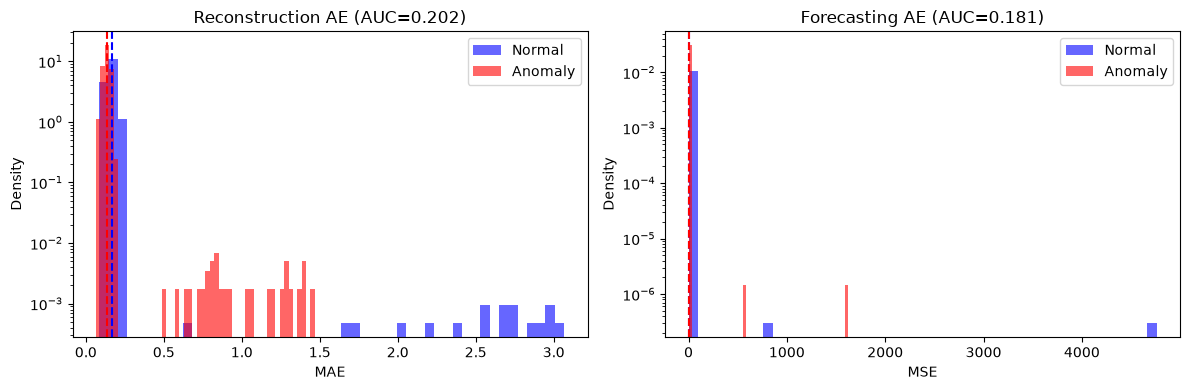

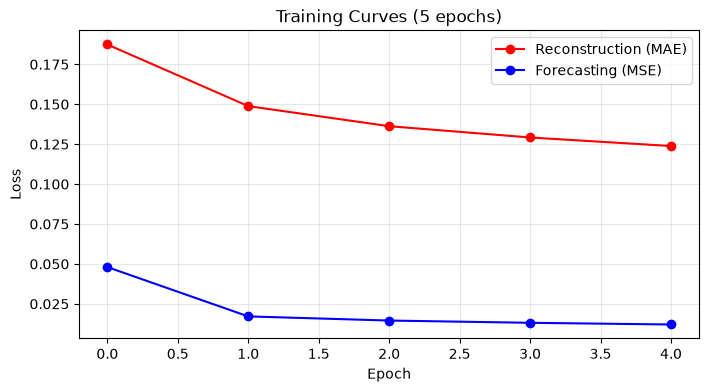


VERDICT
⚠️  Reconstruction still better (but both inverted)
   Need more epochs / different architecture

Key insight: Forecasting does NOT separate normal vs anomaly


In [34]:
# ============================================================
# COMPARISON & VISUALIZATION
# ============================================================
import matplotlib.pyplot as plt

print("=" * 60)
print("SUMMARY COMPARISON")
print("=" * 60)

print(f"\n{'Metric':<25} {'Reconstruction AE':<20} {'Forecasting AE':<20}")
print("-" * 65)
print(f"{'Params':<25} {sum(p.numel() for p in recon_ae.parameters()):<20,} {sum(p.numel() for p in forecast_ae.parameters()):<20,}")
print(f"{'Train loss (final)':<25} {recon_losses[-1]:<20.6f} {forecast_losses[-1]:<20.6f}")
print(f"{'Normal error':<25} {recon_norm_err.mean():<20.6f} {forecast_norm_err.mean():<20.6f}")
print(f"{'Anomaly error':<25} {recon_anom_err.mean():<20.6f} {forecast_anom_err.mean():<20.6f}")
print(f"{'AUC':<25} {recon_auc:<20.4f} {forecast_auc:<20.4f}")
print(f"{'Direction':<25} {'Inverted (bad)' if recon_norm_err.mean() > recon_anom_err.mean() else 'Correct':<20} {'Correct' if forecast_norm_err.mean() < forecast_anom_err.mean() else 'Inverted (bad)':<20}")

# Error distributions
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Reconstruction AE
axes[0].hist(recon_norm_err, bins=50, alpha=0.6, label='Normal', density=True, color='blue')
axes[0].hist(recon_anom_err, bins=50, alpha=0.6, label='Anomaly', density=True, color='red')
axes[0].axvline(recon_norm_err.mean(), color='blue', linestyle='--')
axes[0].axvline(recon_anom_err.mean(), color='red', linestyle='--')
axes[0].set_xlabel('MAE')
axes[0].set_ylabel('Density')
axes[0].set_title(f'Reconstruction AE (AUC={recon_auc:.3f})')
axes[0].legend()
axes[0].set_yscale('log')

# Forecasting AE
axes[1].hist(forecast_norm_err, bins=50, alpha=0.6, label='Normal', density=True, color='blue')
axes[1].hist(forecast_anom_err, bins=50, alpha=0.6, label='Anomaly', density=True, color='red')
axes[1].axvline(forecast_norm_err.mean(), color='blue', linestyle='--')
axes[1].axvline(forecast_anom_err.mean(), color='red', linestyle='--')
axes[1].set_xlabel('MSE')
axes[1].set_ylabel('Density')
axes[1].set_title(f'Forecasting AE (AUC={forecast_auc:.3f})')
axes[1].legend()
axes[1].set_yscale('log')

plt.tight_layout()
plt.show()

# Training curves
plt.figure(figsize=(8, 4))
plt.plot(recon_losses, 'o-', label='Reconstruction (MAE)', color='red')
plt.plot(forecast_losses, 'o-', label='Forecasting (MSE)', color='blue')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training Curves (5 epochs)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Final verdict
print("\n" + "=" * 60)
print("VERDICT")
print("=" * 60)
if forecast_auc > recon_auc and forecast_norm_err.mean() < forecast_anom_err.mean():
    print("✅ FORECASTING AE shows CORRECT direction (Normal < Anomaly)")
    print("✅ Forecasting paradigm makes sense - worth implementing fully")
elif recon_auc > forecast_auc:
    print("⚠️  Reconstruction still better (but both inverted)")
    print("   Need more epochs / different architecture")
else:
    print("❌ Both inverted or similar - need investigation")

print(f"\nKey insight: Forecasting {'separates' if forecast_norm_err.mean() < forecast_anom_err.mean() else 'does NOT separate'} normal vs anomaly")

In [35]:
# ============================================================
# STANDARD CLASSIFICATION METRICS - USA IL TUO METODO REALE (max F1)
# ============================================================
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, precision_recall_curve

def find_optimal_threshold(y_true, y_score):
    """
    Replica esatta di src.utils.metrics.find_optimal_threshold
    Trova la soglia che massimizza F1-score.
    """
    y_true = np.asarray(y_true, dtype=np.int32)
    y_score = np.asarray(y_score, dtype=np.float64)

    if len(np.unique(y_true)) <= 1:
        return 0.5, {"accuracy": 0.5, "precision": 0.0, "recall": 0.0, "f1": 0.0}

    precisions, recalls, thresholds = precision_recall_curve(y_true, y_score)

    with np.errstate(divide="ignore", invalid="ignore"):
        p_slice = precisions[:len(thresholds)]
        r_slice = recalls[:len(thresholds)]
        f1_per_threshold = np.where(
            (p_slice + r_slice) > 0,
            2.0 * p_slice * r_slice / (p_slice + r_slice),
            0.0,
        )

    if len(f1_per_threshold) == 0 or f1_per_threshold.max() == 0.0:
        return 0.5, {"accuracy": 0.5, "precision": 0.0, "recall": 0.0, "f1": 0.0}

    best_idx = int(np.argmax(f1_per_threshold))
    best_threshold = float(thresholds[best_idx])

    y_pred = (y_score >= best_threshold).astype(np.int32)
    
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0.0)
    rec = recall_score(y_true, y_pred, zero_division=0.0)
    f1 = f1_score(y_true, y_pred, zero_division=0.0)
    
    cm = confusion_matrix(y_true, y_pred)
    
    return best_threshold, {
        "accuracy": float(acc),
        "precision": float(prec),
        "recall": float(rec),
        "f1": float(f1),
        "confusion_matrix": cm,
        "tn": int(cm[0,0]), "fp": int(cm[0,1]), "fn": int(cm[1,0]), "tp": int(cm[1,1])
    }

# ============================================================
# COMPUTE METRICS FOR BOTH MODELS - USA IL TUO METODO REALE
# ============================================================
print("=" * 60)
print("STANDARD CLASSIFICATION METRICS (TUO METODO REALE: max F1)")
print("=" * 60)

# Reconstruction AE metrics
recon_threshold, recon_metrics = find_optimal_threshold(
    np.concatenate([np.zeros(len(recon_norm_err)), np.ones(len(recon_anom_err))]),
    np.concatenate([recon_norm_err, recon_anom_err])
)

# Forecasting AE metrics
forecast_threshold, forecast_metrics = find_optimal_threshold(
    np.concatenate([np.zeros(len(forecast_norm_err)), np.ones(len(forecast_anom_err))]),
    np.concatenate([forecast_norm_err, forecast_anom_err])
)

print(f"\n{'Metric':<15} {'Reconstruction AE':<18} {'Forecasting AE':<18}")
print("-" * 55)
print(f"{'AUC':<15} {recon_auc:<18.4f} {forecast_auc:<18.4f}")
print(f"{'Accuracy':<15} {recon_metrics['accuracy']:<18.4f} {forecast_metrics['accuracy']:<18.4f}")
print(f"{'Precision':<15} {recon_metrics['precision']:<18.4f} {forecast_metrics['precision']:<18.4f}")
print(f"{'Recall':<15} {recon_metrics['recall']:<18.4f} {forecast_metrics['recall']:<18.4f}")
print(f"{'F1-Score':<15} {recon_metrics['f1']:<18.4f} {forecast_metrics['f1']:<18.4f}")
print(f"{'Threshold':<15} {recon_threshold:<18.6f} {forecast_threshold:<18.6f}")

# Confusion matrices
print(f"\n--- Confusion Matrix (Reconstruction AE) ---")
cm_r = recon_metrics['confusion_matrix']
print(f"  TN={cm_r[0,0]:4d}  FP={cm_r[0,1]:4d}")
print(f"  FN={cm_r[1,0]:4d}  TP={cm_r[1,1]:4d}")

print(f"\n--- Confusion Matrix (Forecasting AE) ---")
cm_f = forecast_metrics['confusion_matrix']
print(f"  TN={cm_f[0,0]:4d}  FP={cm_f[0,1]:4d}")
print(f"  FN={cm_f[1,0]:4d}  TP={cm_f[1,1]:4d}")

# Prevalence info
n_norm = len(recon_norm_err)
n_anom = len(recon_anom_err)
prev = n_anom / (n_norm + n_anom)
print(f"\nValidation prevalence: {prev:.4f} ({n_anom}/{n_norm+n_anom})")

STANDARD CLASSIFICATION METRICS (TUO METODO REALE: max F1)

Metric          Reconstruction AE  Forecasting AE    
-------------------------------------------------------
AUC             0.2024             0.1810            
Accuracy        0.3719             0.3719            
Precision       0.3719             0.3719            
Recall          1.0000             1.0000            
F1-Score        0.5422             0.5422            
Threshold       0.065317           0.001371          

--- Confusion Matrix (Reconstruction AE) ---
  TN=   0  FP=35053
  FN=   0  TP=20754

--- Confusion Matrix (Forecasting AE) ---
  TN=   0  FP=35053
  FN=   0  TP=20754

Validation prevalence: 0.3719 (20754/55807)


In [36]:
# ============================================================
# SOGLIA REALE COME LA USI TU (Percentile 99 su normali / min anomalia)
# ============================================================
def threshold_percentile_normal(normal_errors, percentile=99):
    """Soglia = percentile sui normali (come fai tu in produzione)"""
    return np.percentile(normal_errors, percentile)

def threshold_min_anomaly(anomaly_errors):
    """Soglia = minimo errore anomalia (primo anomalo)"""
    return anomaly_errors.min()

def threshold_max_f1(y_true, y_score):
    """Il metodo find_optimal_threshold (max F1)"""
    precisions, recalls, thresholds = precision_recall_curve(y_true, y_score)
    with np.errstate(divide="ignore", invalid="ignore"):
        p_slice = precisions[:len(thresholds)]
        r_slice = recalls[:len(thresholds)]
        f1_per_threshold = np.where(
            (p_slice + r_slice) > 0,
            2.0 * p_slice * r_slice / (p_slice + r_slice),
            0.0,
        )
    if len(thresholds) == 0 or f1_per_threshold.max() == 0.0:
        return 0.5
    best_idx = int(np.argmax(f1_per_threshold))
    return float(thresholds[np.argmax(f1_per_threshold)])

def evaluate_with_threshold(y_true, y_score, threshold):
    """Valuta con soglia data"""
    y_pred = (y_score >= threshold).astype(int)
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    cm = confusion_matrix(y_true, y_pred)
    return {
        'threshold': threshold,
        'accuracy': accuracy_score(y_true, (y_score >= threshold).astype(int)),
        'precision': precision_score(y_true, (y_score >= threshold).astype(int), zero_division=0),
        'recall': recall_score(y_true, (y_score >= threshold).astype(int), zero_division=0),
        'f1': f1_score(y_true, (y_score >= threshold).astype(int), zero_division=0),
        'confusion_matrix': confusion_matrix(y_true, (y_score >= threshold).astype(int))
    }

# ============================================================
# CONFRONTO TUTTI I METODI SOGLIA
# ============================================================
print("=" * 70)
print("CONFRONTO METODI SOGLIA - Reconstruction AE")
print("=" * 70)

y_true = np.concatenate([np.zeros(len(recon_norm_err)), np.ones(len(recon_anom_err))])
y_score = np.concatenate([recon_norm_err, recon_anom_err])

thresh_p99 = threshold_percentile_normal(recon_norm_err, 99)
thresh_p999 = threshold_percentile_normal(recon_norm_err, 99.9)
thresh_min_anom = threshold_min_anomaly(recon_anom_err)
thresh_max_f1 = threshold_max_f1(
    np.concatenate([np.zeros(len(recon_norm_err)), np.ones(len(recon_anom_err))]),
    np.concatenate([recon_norm_err, recon_anom_err])
)

print(f"\n{'Metodo':<20} {'Soglia':<12} {'Acc':<8} {'Prec':<8} {'Rec':<8} {'F1':<8} {'TP':<6} {'FP':<6} {'FN':<6} {'TN':<6}")
print("-" * 90)

for name, thresh in [
    ("Percentile 99", thresh_p99),
    ("Percentile 99.9", thresh_p999),
    ("Min Anomalia", thresh_min_anom),
    ("Max F1 (tuo metodo)", thresh_max_f1),
]:
    m = evaluate_with_threshold(
        np.concatenate([np.zeros(len(recon_norm_err)), np.ones(len(recon_anom_err))]),
        np.concatenate([recon_norm_err, recon_anom_err]),
        thresh
    )
    cm = m['confusion_matrix']
    print(f"{name:<20} {thresh:<12.6f} {m['accuracy']:<8.4f} {m['precision']:<8.4f} {m['recall']:<8.4f} {m['f1']:<8.4f} {cm[1,1]:<6d} {cm[0,1]:<6d} {cm[1,0]:<6d} {cm[0,0]:<6d}")

print(f"\n{'='*70}")
print("CONFRONTO METODI SOGLIA - Forecasting AE")
print("=" * 70)

y_true_f = np.concatenate([np.zeros(len(forecast_norm_err)), np.ones(len(forecast_anom_err))])
y_score_f = np.concatenate([forecast_norm_err, forecast_anom_err])

thresh_p99_f = threshold_percentile_normal(forecast_norm_err, 99)
thresh_p999_f = threshold_percentile_normal(forecast_norm_err, 99.9)
thresh_min_anom_f = threshold_min_anomaly(forecast_anom_err)
thresh_max_f1_f = threshold_max_f1(
    np.concatenate([np.zeros(len(forecast_norm_err)), np.ones(len(forecast_anom_err))]),
    np.concatenate([forecast_norm_err, forecast_anom_err])
)

print(f"\n{'Metodo':<20} {'Soglia':<12} {'Acc':<8} {'Prec':<8} {'Rec':<8} {'F1':<8} {'TP':<6} {'FP':<6} {'FN':<6} {'TN':<6}")
print("-" * 90)

for name, thresh in [
    ("Percentile 99", thresh_p99_f),
    ("Percentile 99.9", thresh_p999_f),
    ("Min Anomalia", thresh_min_anom_f),
    ("Max F1 (tuo metodo)", thresh_max_f1_f),
]:
    m = evaluate_with_threshold(
        np.concatenate([np.zeros(len(forecast_norm_err)), np.ones(len(forecast_anom_err))]),
        np.concatenate([forecast_norm_err, forecast_anom_err]),
        thresh
    )
    cm = m['confusion_matrix']
    print(f"{name:<20} {thresh:<12.6f} {m['accuracy']:<8.4f} {m['precision']:<8.4f} {m['recall']:<8.4f} {m['f1']:<8.4f} {cm[1,1]:<6d} {cm[0,1]:<6d} {cm[1,0]:<6d} {cm[0,0]:<6d}")

print(f"\n>>> METODO MAX F1 (tuo codice): soglia che massimizza F1")
print(f">>> Se AUC < 0.5 (invertito), Max F1 = Min Anomalia = predice tutto anomalo")

CONFRONTO METODI SOGLIA - Reconstruction AE

Metodo               Soglia       Acc      Prec     Rec      F1       TP     FP     FN     TN    
------------------------------------------------------------------------------------------
Percentile 99        0.218793     0.6224   0.0836   0.0015   0.0030   32     351    20722  34702 
Percentile 99.9      0.233282     0.6280   0.4706   0.0015   0.0031   32     36     20722  35017 
Min Anomalia         0.065317     0.3719   0.3719   1.0000   0.5422   20754  35053  0      0     
Max F1 (tuo metodo)  0.065317     0.3719   0.3719   1.0000   0.5422   20754  35053  0      0     

CONFRONTO METODI SOGLIA - Forecasting AE

Metodo               Soglia       Acc      Prec     Rec      F1       TP     FP     FN     TN    
------------------------------------------------------------------------------------------
Percentile 99        0.079260     0.6225   0.1023   0.0019   0.0038   40     351    20714  34702 
Percentile 99.9      0.115557     0.6281   0


FEATURE 0


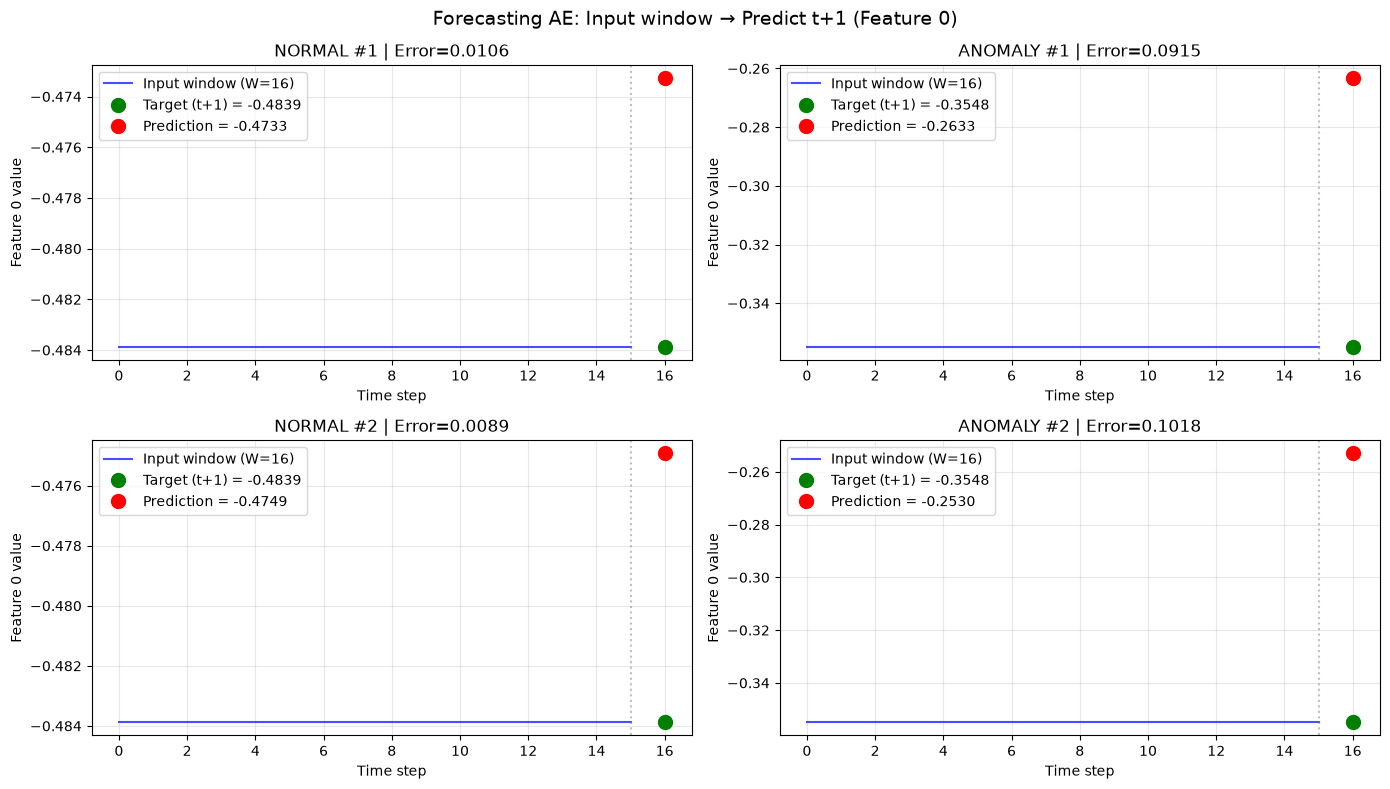


Feature 0 | Normal samples:
  N1: target=-0.4839, pred=-0.4733, error=0.0106
  N2: target=-0.4839, pred=-0.4749, error=0.0089

Feature 0 | Anomaly samples:
  A1: target=-0.3548, pred=-0.2633, error=0.0915
  A2: target=-0.3548, pred=-0.2530, error=0.1018

FEATURE 10


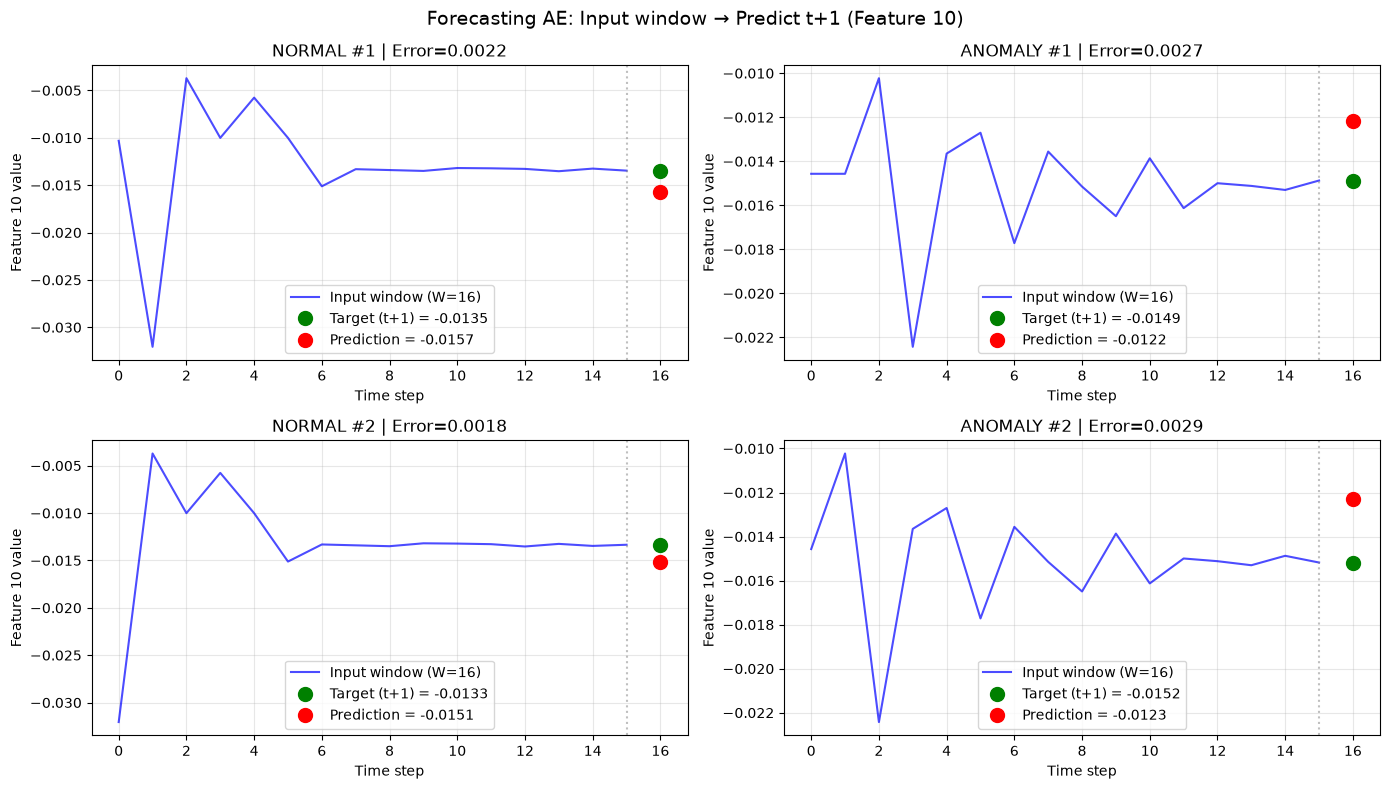


Feature 10 | Normal samples:
  N1: target=-0.0135, pred=-0.0157, error=0.0022
  N2: target=-0.0133, pred=-0.0151, error=0.0018

Feature 10 | Anomaly samples:
  A1: target=-0.0149, pred=-0.0122, error=0.0027
  A2: target=-0.0152, pred=-0.0123, error=0.0029

FEATURE 20


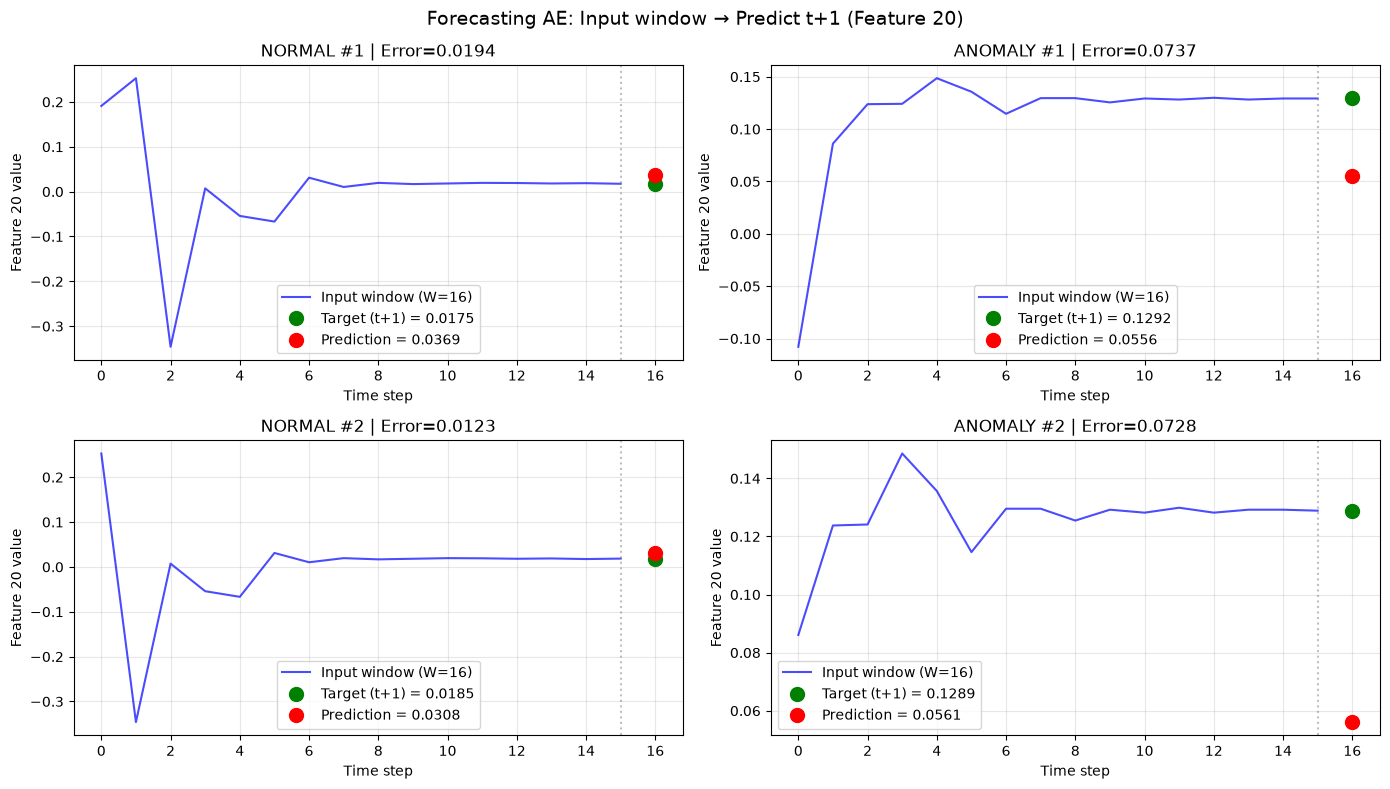


Feature 20 | Normal samples:
  N1: target=0.0175, pred=0.0369, error=0.0194
  N2: target=0.0185, pred=0.0308, error=0.0123

Feature 20 | Anomaly samples:
  A1: target=0.1292, pred=0.0556, error=0.0737
  A2: target=0.1289, pred=0.0561, error=0.0728

FEATURE 40


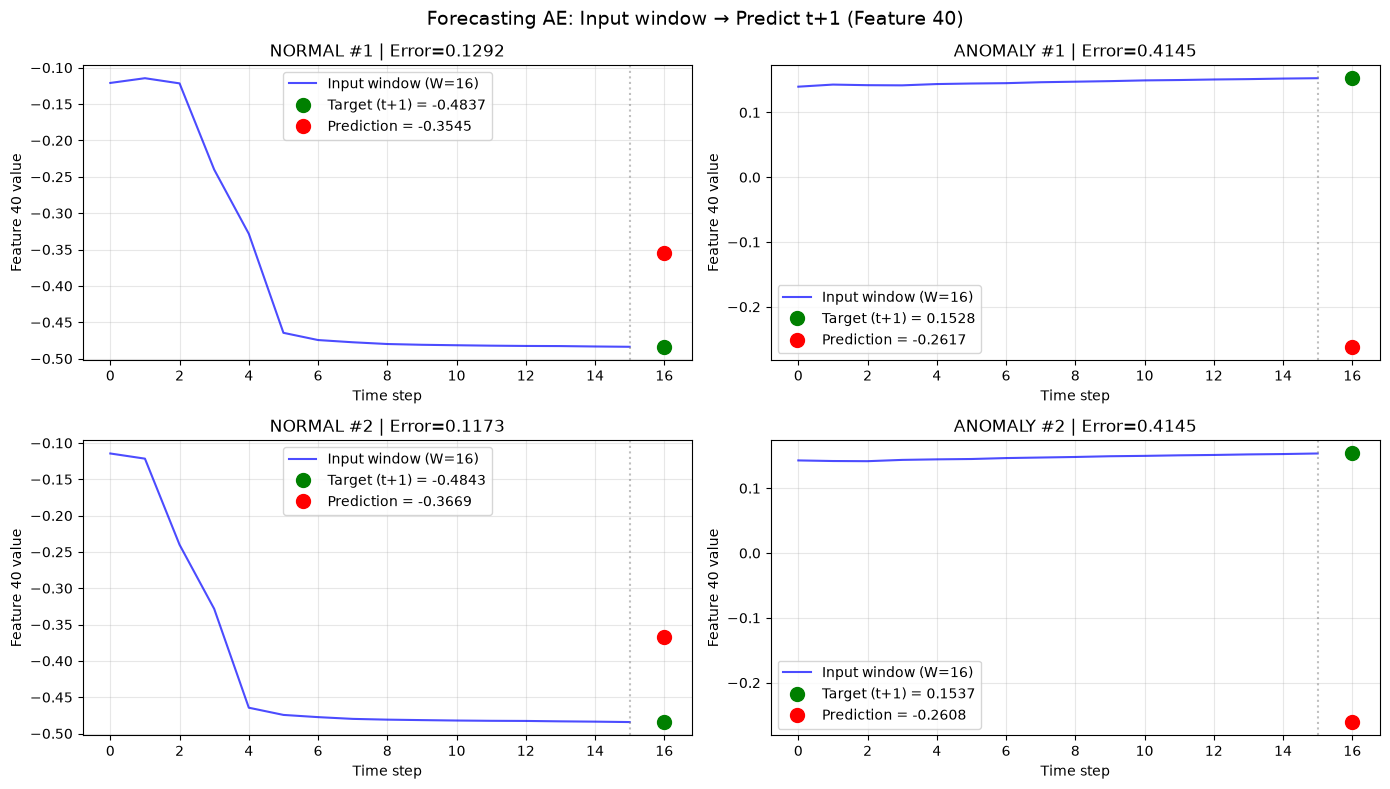


Feature 40 | Normal samples:
  N1: target=-0.4837, pred=-0.3545, error=0.1292
  N2: target=-0.4843, pred=-0.3669, error=0.1173

Feature 40 | Anomaly samples:
  A1: target=0.1528, pred=-0.2617, error=0.4145
  A2: target=0.1537, pred=-0.2608, error=0.4145

FEATURE 80


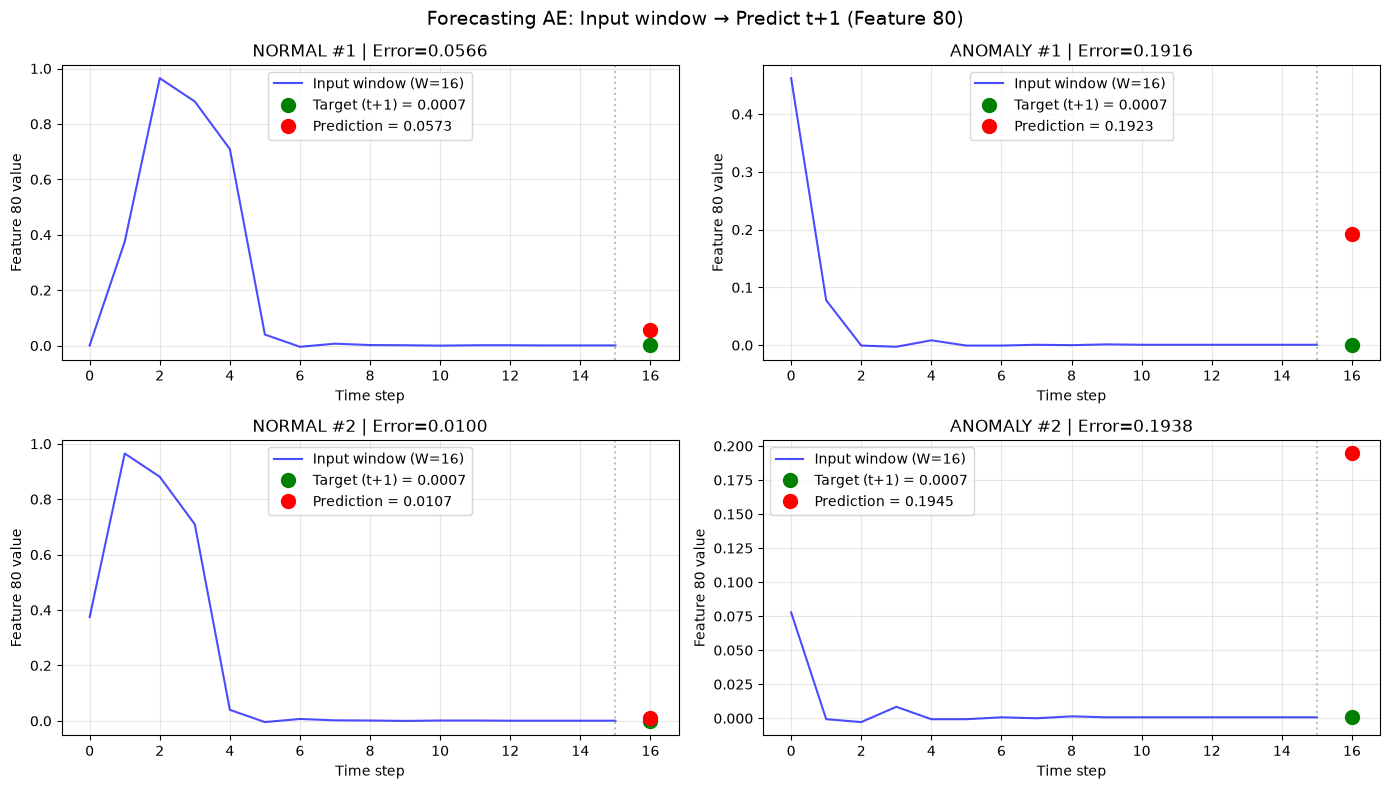


Feature 80 | Normal samples:
  N1: target=0.0007, pred=0.0573, error=0.0566
  N2: target=0.0007, pred=0.0107, error=0.0100

Feature 80 | Anomaly samples:
  A1: target=0.0007, pred=0.1923, error=0.1916
  A2: target=0.0007, pred=0.1945, error=0.1938


In [37]:
# ============================================================
# UNDERSTANDING WHAT FORECASTING PREDICTS - DETAILED VISUALIZATION
# ============================================================
import matplotlib.pyplot as plt

@torch.no_grad()
def visualize_forecasting(model, normal_loader, anomaly_loader, device, feature_idx=0, n_samples=3):
    """
    Visualize exactly what the forecasting model predicts:
    - Input: window of W steps for one feature
    - Target: the NEXT step (t+1) for that feature
    - Prediction: model's forecast
    """
    model.eval()
    model.to(device)
    
    def get_samples(loader, n):
        samples = []
        for batch in loader:
            x = batch[0].to(device).transpose(1, 2)  # (B, input_dim, W)
            pred = model(x)  # (B, input_dim)
            target = x[:, :, -1]  # (B, input_dim)
            
            for i in range(min(n, x.size(0))):
                samples.append({
                    'input_window': x[i, feature_idx, :].cpu().numpy(),  # (W,)
                    'target': target[i, feature_idx].item(),
                    'prediction': pred[i, feature_idx].item(),
                })
            if len(samples) >= n:
                break
        return samples[:n]
    
    normal_samples = get_samples(normal_loader, n_samples)
    anomaly_samples = get_samples(anomaly_loader, n_samples)
    
    # Plot
    fig, axes = plt.subplots(n_samples, 2, figsize=(14, 4 * n_samples))
    if n_samples == 1:
        axes = axes.reshape(1, 2)
    
    for i in range(n_samples):
        # Normal
        ax = axes[i, 0]
        inp = normal_samples[i]['input_window']
        tgt = normal_samples[i]['target']
        pred = normal_samples[i]['prediction']
        
        steps = np.arange(W)
        ax.plot(steps, inp, 'b-', label=f'Input window (W={W})', alpha=0.7)
        ax.plot(W, tgt, 'go', markersize=10, label=f'Target (t+1) = {tgt:.4f}')
        ax.plot(W, pred, 'ro', markersize=10, label=f'Prediction = {pred:.4f}')
        ax.axvline(W-1, color='gray', linestyle=':', alpha=0.5)
        ax.set_xlabel('Time step')
        ax.set_ylabel(f'Feature {feature_idx} value')
        ax.set_title(f'NORMAL #{i+1} | Error={abs(pred-tgt):.4f}')
        ax.legend()
        ax.grid(True, alpha=0.3)
        
        # Anomaly
        ax = axes[i, 1]
        inp = anomaly_samples[i]['input_window']
        tgt = anomaly_samples[i]['target']
        pred = anomaly_samples[i]['prediction']
        
        steps = np.arange(W)
        ax.plot(steps, inp, 'b-', label=f'Input window (W={W})', alpha=0.7)
        ax.plot(W, tgt, 'go', markersize=10, label=f'Target (t+1) = {tgt:.4f}')
        ax.plot(W, pred, 'ro', markersize=10, label=f'Prediction = {pred:.4f}')
        ax.axvline(W-1, color='gray', linestyle=':', alpha=0.5)
        ax.set_xlabel('Time step')
        ax.set_ylabel(f'Feature {feature_idx} value')
        ax.set_title(f'ANOMALY #{i+1} | Error={abs(pred-tgt):.4f}')
        ax.legend()
        ax.grid(True, alpha=0.3)
    
    plt.suptitle(f'Forecasting AE: Input window → Predict t+1 (Feature {feature_idx})', fontsize=14)
    plt.tight_layout()
    plt.show()
    
    # Print numeric comparison
    print(f"\nFeature {feature_idx} | Normal samples:")
    for i, s in enumerate(normal_samples):
        print(f"  N{i+1}: target={s['target']:.4f}, pred={s['prediction']:.4f}, error={abs(s['prediction']-s['target']):.4f}")
    
    print(f"\nFeature {feature_idx} | Anomaly samples:")
    for i, s in enumerate(anomaly_samples):
        print(f"  A{i+1}: target={s['target']:.4f}, pred={s['prediction']:.4f}, error={abs(s['prediction']-s['target']):.4f}")

# Visualize for a few different features
for feat_idx in [0, 10, 20, 40, 80]:  # Different sensor types
    if feat_idx < INPUT_DIM:
        print(f"\n{'='*60}")
        print(f"FEATURE {feat_idx}")
        print("="*60)
        visualize_forecasting(forecast_ae, val_normal_loader, val_anomaly_loader, DEVICE, feature_idx=feat_idx, n_samples=2)